# Proyecto 2 — Parte 3: Pronósticos BG/NBD vs. series de tiempo
**Business Intelligence · CDNOW · 1997–1998**

Notebook reproducible para los incisos **3.1, 3.2, 3.3 y 3.4**. Incluye carga y preparación de CDNOW, estimación BG/NBD por máxima verosimilitud (si no se proporcionan los parámetros de la Parte 2), gráficas, comparación de pronósticos y análisis por cliente.

**Importante:** los resultados no están precalculados: ejecuta las celdas con `CDNOW sample.txt`. No se usan datos inventados.

**Archivo de entrada:** `CDNOW_sample.zip` con `CDNOW_sample.txt` dentro, en la misma carpeta del notebook.

## 0. Preparación
Coloca `CDNOW sample.txt` en la misma carpeta que este notebook. El archivo tiene cinco columnas sin encabezado: ID completo, ID de muestra, fecha AAAAMMDD, cantidad y monto. Las compras del mismo cliente en la misma fecha se consideran una transacción.

In [1]:
# Si falta alguna dependencia, ejecuta esta línea una vez:
# %pip install numpy pandas scipy matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import hyp2f1, gammaln, betaln, logsumexp
from scipy.optimize import minimize
from pathlib import Path

INICIO = pd.Timestamp('1997-01-01')
FIN_CAL = pd.Timestamp('1997-09-30')
INICIO_HOLD = pd.Timestamp('1997-10-01')
FIN_HOLD = pd.Timestamp('1998-06-30')

import zipfile
import pandas as pd

ARCHIVO = "CDNOW_sample.zip"

with zipfile.ZipFile(ARCHIVO, "r") as z:
    with z.open("CDNOW_sample.txt") as archivo:
        raw = pd.read_csv(
            archivo,
            sep=r"\s+",
            header=None,
            names=[
                "id_completo",
                "cliente",
                "fecha",
                "cantidad",
                "monto"
            ]
        )

raw["fecha"] = pd.to_datetime(
    raw["fecha"].astype(str),
    format="%Y%m%d"
)

compras = (
    raw.groupby(
        ["cliente", "fecha"],
        as_index=False
    )
    .agg(
        cantidad=("cantidad", "sum"),
        monto=("monto", "sum")
    )
)

compras = compras.sort_values(
    ["cliente", "fecha"]
).reset_index(drop=True)

print("Clientes:", compras.cliente.nunique())
print("Transacciones:", len(compras))

display(compras.head())


Clientes: 2357
Transacciones: 6696


,cliente,fecha,cantidad,monto
0,1,1997-01-01,2,29.33
1,1,1997-01-18,2,29.73
2,1,1997-08-02,1,14.96
3,1,1997-12-12,2,26.48
4,2,1997-01-01,3,63.34


### Preparación del calendario y de la historia individual
El período de evaluación son las **semanas 40–78**. Para graficar, usamos intervalos consecutivos de siete días a partir del 1 de enero de 1997; la semana 78 incluye hasta el 30 de junio de 1998 (el último intervalo puede quedar truncado). La partición de calibración/holdout usa las **fechas exactas del enunciado**. Esto implica que los intervalos semanales y la fecha de corte no coinciden perfectamente; se documenta esta convención para evitar mezclar información futura en el entrenamiento.

In [2]:
primera = compras.groupby('cliente')['fecha'].min().rename('primera')
compras = compras.join(primera, on='cliente')
compras['repetida'] = compras['fecha'] > compras['primera']
compras['semana'] = ((compras['fecha'] - INICIO).dt.days // 7 + 1).astype(int)

cal = compras[compras.fecha <= FIN_CAL].copy()
hold = compras[(compras.fecha >= INICIO_HOLD) & (compras.fecha <= FIN_HOLD)].copy()

def historial_cliente(g):
    fechas = g.fecha.sort_values()
    f0 = fechas.iloc[0]
    return pd.Series({
        'primera': f0,
        'x': len(fechas)-1,
        'tx': (fechas.iloc[-1]-f0).days/7 if len(fechas)>1 else 0.,
        'T': (FIN_CAL-f0).days/7
    })
clientes = cal.groupby('cliente').apply(historial_cliente, include_groups=False)
clientes['x_hold'] = hold.groupby('cliente').size().reindex(clientes.index, fill_value=0)
clientes['semana_inicio'] = ((clientes.primera-INICIO).dt.days//7 + 1).astype(int)
assert (clientes.T if False else clientes['T']).ge(clientes.tx).all()
assert (clientes['T'] >= 0).all()
display(clientes.head())
print('Clientes en calibración:',len(clientes))
print('Compras holdout:',clientes.x_hold.sum())

,primera,x,tx,T,x_hold,semana_inicio
cliente,,,,,,
1,1997-01-01,2,30.428571,38.857143,1,1
2,1997-01-01,1,1.714286,38.857143,0,1
3,1997-01-01,0,0.000000,38.857143,0,1
4,1997-01-01,0,0.000000,38.857143,0,1
5,1997-01-01,0,0.000000,38.857143,0,1


Clientes en calibración: 2357
Compras holdout: 1882


## Estimación de parámetros BG/NBD (apoyo de la Parte 2)
Si ya estimaste `r`, `alpha`, `a`, `b` en la Parte 2, puedes sustituirlos en la celda posterior. Si no, se estiman mediante máxima verosimilitud. La parametrización usa `Gamma(r, tasa=alpha)` y `Beta(a,b)`.

La log-verosimilitud implementa las dos posibilidades: cliente activo hasta el fin de observación o abandono después de la última recompra.

In [3]:
def loglik_bgnbd(theta_log, x, tx, T):
    r, alpha, a, b = np.exp(theta_log)
    A1 = gammaln(r+x)-gammaln(r)+r*np.log(alpha)
    A2 = gammaln(a+b)+gammaln(b+x)-gammaln(b)-gammaln(a+b+x)
    activo = -(r+x)*np.log(alpha+T)
    abandono = np.full_like(x, -np.inf, dtype=float)
    mask = x>0
    abandono[mask] = (np.log(a)-np.log(b+x[mask]-1)
                       -(r+x[mask])*np.log(alpha+tx[mask]))
    return A1 + A2 + np.logaddexp(activo, abandono)

x = clientes.x.to_numpy(dtype=float)
tx = clientes.tx.to_numpy(dtype=float)
T = clientes['T'].to_numpy(dtype=float)

def objetivo(theta):
    ll = loglik_bgnbd(theta,x,tx,T)
    return -np.sum(ll) if np.isfinite(ll).all() else 1e100

inicios = [[0.5, 5, 1.5, 3], [1, 10, 2, 5], [0.2, 2, 2, 4]]
ajustes = [minimize(objetivo, np.log(v), method='L-BFGS-B',
                    bounds=[(-12,12)]*4) for v in inicios]
mejor = min(ajustes,key=lambda q:q.fun)
if not mejor.success:
    print('Advertencia: revisar convergencia:', mejor.message)
r, alpha, a, b = np.exp(mejor.x)
print(dict(r=r, alpha=alpha, a=a, b=b))
print('Log-verosimilitud:',-mejor.fun)

# Para usar los parámetros estimados en tu Parte 2, descomenta y edita:
# r, alpha, a, b = 0.0, 0.0, 0.0, 0.0
assert min(r,alpha,a,b)>0
if a < 1:
    print('Nota: a < 1 es válido; no debe confundirse con a = 1.')

{'r': np.float64(0.24259444149884915), 'alpha': np.float64(4.41359782711311), 'a': np.float64(0.7929118198273818), 'b': np.float64(2.425868821625821)}
Log-verosimilitud: -9582.429206675535
Nota: a < 1 es válido; no debe confundirse con a = 1.


## 3.1 Bottom-up: pronóstico por cohorte
La esperanza de compras repetidas de un cliente con antigüedad `t` desde su primera compra es:

\[
E[X(t)] = \frac{a+b-1}{a-1}\left[1-\left(\frac{\alpha}{\alpha+t}\right)^r {}_2F_1\left(r,b;a+b-1;\frac{t}{\alpha+t}\right)\right].
\]

Se suman las esperanzas para todos los clientes, desplazadas según su primera compra. La fórmula es válida para a < 1 (excepto el caso singular a = 1, que requiere un límite). El valor observado cuenta compras repetidas (no la primera compra).

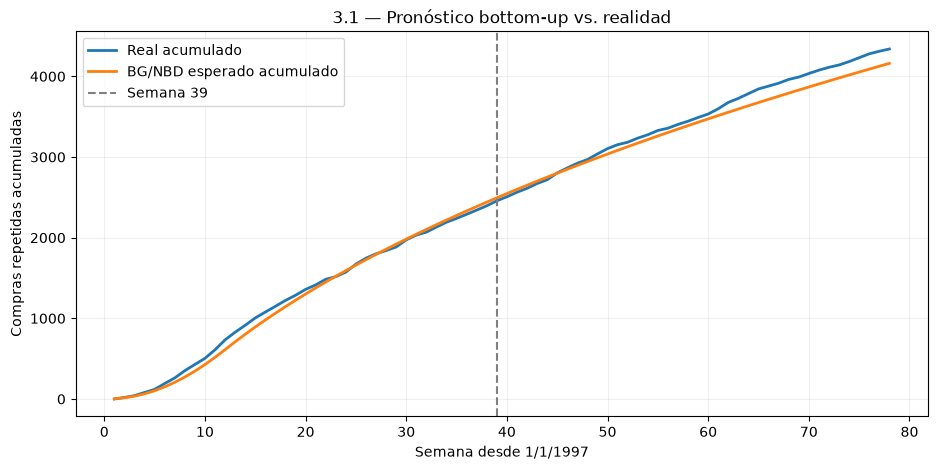

Pronóstico BG/NBD semanas 40–78: 1666.66
Real semanas 40–78: 1882


In [4]:
# 3.1: esperanza incondicional BG/NBD y curva acumulada
from scipy.special import hyp2f1

def ex_repetidas(t):
    t = np.maximum(np.asarray(t, dtype=float), 0)
    if np.isclose(a, 1.0, atol=1e-7):
        raise ValueError("a está demasiado cerca de 1; se requiere evaluación por límite.")
    z = t / (alpha + t)
    return ((a+b-1)/(a-1)) * (
        1 - (alpha/(alpha+t))**r *
        hyp2f1(r, b, a+b-1, z)
    )

semanas = np.arange(1, 79)
dias_corte = np.minimum(semanas*7-1, (FIN_HOLD-INICIO).days)
dias_primera = (clientes['primera']-INICIO).dt.days.to_numpy()
edad = np.maximum((dias_corte[:,None]-dias_primera[None,:])/7, 0)
pred_acum = np.sum(ex_repetidas(edad), axis=1)

real_semanal = (compras.loc[compras.repetida & compras.fecha.le(FIN_HOLD)]
                .groupby('semana').size().reindex(semanas, fill_value=0))
real_acum = real_semanal.cumsum().to_numpy()

plt.figure(figsize=(11,5))
plt.plot(semanas, real_acum, label='Real acumulado', lw=2)
plt.plot(semanas, pred_acum, label='BG/NBD esperado acumulado', lw=2)
plt.axvline(39, ls='--', color='gray', label='Semana 39')
plt.xlabel('Semana desde 1/1/1997')
plt.ylabel('Compras repetidas acumuladas')
plt.title('3.1 — Pronóstico bottom-up vs. realidad')
plt.legend(); plt.grid(alpha=.2); plt.show()
print('Pronóstico BG/NBD semanas 40–78:', round(pred_acum[-1]-pred_acum[38], 2))
print('Real semanas 40–78:', int(real_semanal.loc[40:78].sum()))


## 3.2 Top-down: pronóstico agregado
Se usan únicamente las primeras 39 observaciones semanales. Se comparan cuatro familias: media histórica, naïve, media móvil de 4 y 8 semanas, y tendencia lineal con ventanas de 13 y 26 semanas. Los pronósticos negativos se truncan a cero.

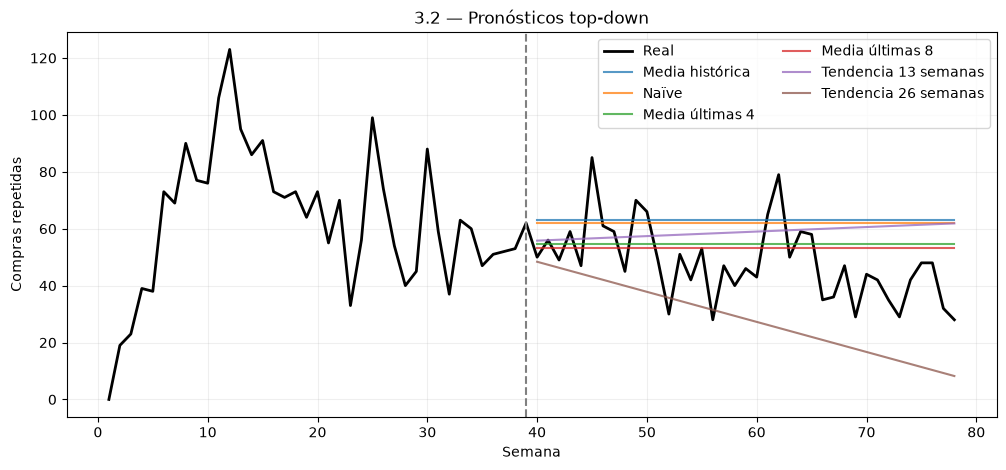

In [5]:
train = real_semanal.loc[1:39].astype(float)
test = real_semanal.loc[40:78].astype(float)
h = np.arange(1,40)
pronosticos = {}
pronosticos['Media histórica'] = np.repeat(train.mean(),39)
pronosticos['Naïve'] = np.repeat(train.iloc[-1],39)
for v in [4,8]:
    pronosticos[f'Media últimas {v}'] = np.repeat(train.iloc[-v:].mean(),39)
for v in [13,26]:
    ys = train.iloc[-v:].to_numpy()
    xs = np.arange(39-v+1,40)
    m,c = np.polyfit(xs,ys,1)
    pronosticos[f'Tendencia {v} semanas'] = np.maximum(m*np.arange(40,79)+c,0)

plt.figure(figsize=(12,5))
plt.plot(np.arange(1,79),real_semanal.values,label='Real',color='black',lw=2)
for nombre,yhat in pronosticos.items():
    plt.plot(np.arange(40,79),yhat,label=nombre,alpha=.75)
plt.axvline(39,color='gray',ls='--')
plt.title('3.2 — Pronósticos top-down');plt.xlabel('Semana')
plt.ylabel('Compras repetidas');plt.legend(ncol=2);plt.grid(alpha=.2);plt.show()

## 3.3 Comparación de modelos
El error porcentual firmado se calcula como `(pronóstico − real)/real × 100`. El **MAE semanal** es la media de los errores absolutos semanales. Para la comparación se deriva el pronóstico semanal BG/NBD restando acumulados sucesivos.

**Precaución metodológica:** el BG/NBD incondicional de 3.1 se ajustó con calibración y pronostica desde el inicio de cada cliente; para una comparación estrictamente fuera de muestra, los métodos deben evaluarse sobre los mismos cortes temporales. La convención semanal puede diferir en hasta unos días del corte calendario exacto.

In [6]:
# BG/NBD semanal: incrementos del acumulado
pred_sem_bgnbd = np.diff(np.r_[0,pred_acum])[39:78]
pronosticos['BG/NBD bottom-up'] = pred_sem_bgnbd
real_h = test.to_numpy()
total_real = real_h.sum()
filas = []
for nombre,p in pronosticos.items():
    p = np.asarray(p,float)
    filas.append({
        'Método':nombre,
        'Total pronosticado':round(p.sum(),2),
        'Total real':int(total_real),
        'Error porcentual (%)':round(100*(p.sum()-total_real)/total_real,2),
        'MAE semanal':round(np.mean(np.abs(p-real_h)),2)
    })
tabla = pd.DataFrame(filas).sort_values('MAE semanal')
display(tabla)
print('Mejor MAE:',tabla.iloc[0]['Método'])
print('Compras repetidas semanas 1–12:',int(real_semanal.loc[1:12].sum()))
tabla.to_csv('parte3_comparacion_modelos.csv',index=False)

,Método,Total pronosticado,Total real,Error porcentual (%),MAE semanal
6,BG/NBD bottom-up,1666.66,1882,-11.44,9.82
3,Media últimas 8,2071.88,1882,10.09,11.67
2,Media últimas 4,2125.50,1882,12.94,12.27
4,Tendencia 13 semanas,2294.57,1882,21.92,14.90
1,Naïve,2418.00,1882,28.48,16.56
0,Media histórica,2457.00,1882,30.55,17.31
5,Tendencia 26 semanas,1104.07,1882,-41.34,20.42


Mejor MAE: BG/NBD bottom-up
Compras repetidas semanas 1–12: 733


In [7]:

print("r =", r)
print("alpha =", alpha)
print("a =", a)
print("b =", b)


r = 0.24259444149884915
alpha = 4.41359782711311
a = 0.7929118198273818
b = 2.425868821625821


## 3.4 Pronóstico por cliente condicionado a su historia
Para cada cliente se calcula `E[Y(39) | x, tx, T]` con la fórmula condicional del enunciado. Se agrupan por `x` de calibración: 0,1,...,6 y 7+. Se compara la media pronosticada y observada `x*`.

\[
A=\frac{\alpha+T}{\alpha+T+\tau},\quad
D=1+\mathbf{1}_{x>0}\frac{a}{b+x-1}
\left(\frac{\alpha+T}{\alpha+t_x}\right)^{r+x}.
\]

,clientes,promedio_predicho,promedio_real,error
grupo,,,,
0,1411,0.225087,0.236712,-0.011624
1,439,0.523131,0.697039,-0.173908
2,214,1.044136,1.392523,-0.348388
3,100,1.520284,1.560000,-0.039716
4,62,2.163873,2.532258,-0.368385
5,38,2.653855,2.947368,-0.293513
6,29,3.504056,3.862069,-0.358013
7+,64,6.157215,6.359375,-0.202160


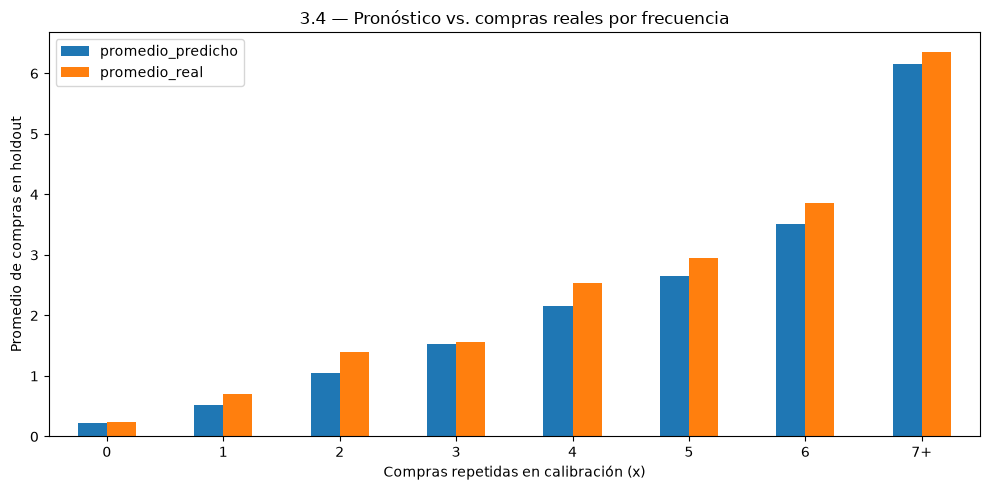

In [8]:
def pronostico_condicional(x,tx,T,tau=39):
    x=np.asarray(x,float); tx=np.asarray(tx,float); T=np.asarray(T,float)
    A=(alpha+T)/(alpha+T+tau)
    D=np.ones_like(x)
    mask=x>0
    D[mask] += (a/(b+x[mask]-1))*(
        (alpha+T[mask])/(alpha+tx[mask]))**(r+x[mask])
    if np.isclose(a, 1.0, atol=1e-7):
        raise ValueError('a está demasiado cerca de 1; requiere evaluación por límite.')
    num = 1-A**(r+x)*hyp2f1(r+x,b+x,a+b+x-1,1-A)
    return ((a+b+x-1)/(a-1))*num/D

clientes['pred_hold'] = pronostico_condicional(x,tx,T,39)
clientes['grupo'] = clientes.x.apply(lambda n:str(int(n)) if n<7 else '7+')
grupos = (clientes.groupby('grupo')
          .agg(clientes=('x','size'),
               promedio_predicho=('pred_hold','mean'),
               promedio_real=('x_hold','mean'))
          .reindex([str(i) for i in range(7)]+['7+']))
grupos['error'] = grupos.promedio_predicho-grupos.promedio_real
display(grupos)
ax=grupos[['promedio_predicho','promedio_real']].plot.bar(figsize=(10,5))
ax.set_title('3.4 — Pronóstico vs. compras reales por frecuencia')
ax.set_xlabel('Compras repetidas en calibración (x)')
ax.set_ylabel('Promedio de compras en holdout')
plt.xticks(rotation=0);plt.tight_layout();plt.show()
grupos.to_csv('parte3_por_cliente.csv')

## Conclusiones de la Parte 3 — Pronósticos y comparación de modelos

### 3.1. Pronóstico Bottom-up mediante BG/NBD

El enfoque Bottom-up permite estimar el comportamiento futuro de compra a partir de las características individuales de los clientes. Mediante el modelo BG/NBD, se calcula el número esperado de compras repetidas y posteriormente se agregan las estimaciones para obtener un pronóstico general.

La comparación entre las compras acumuladas reales y las estimadas permite evaluar la capacidad del modelo para representar el comportamiento de compra de la población analizada. Este enfoque resulta útil porque considera la heterogeneidad entre clientes y permite construir pronósticos a partir de información individual.

### 3.2. Pronóstico Top-down mediante métodos agregados

El enfoque Top-down utiliza el comportamiento histórico de las compras semanales para generar pronósticos agregados. Se consideran métodos como la media histórica, el pronóstico naïve, las medias móviles de 4 y 8 semanas y las tendencias lineales de 13 y 26 semanas.

Los métodos basados en promedios producen pronósticos constantes durante el horizonte evaluado, mientras que los métodos de tendencia permiten proyectar incrementos o disminuciones en las compras. Por lo tanto, la selección del método debe considerar tanto la estabilidad del comportamiento histórico como su capacidad predictiva.

### 3.3. Comparación del desempeño de los modelos

La comparación de los métodos de pronóstico se realiza mediante el error porcentual total y el error absoluto medio (MAE). Estas métricas permiten evaluar dos aspectos diferentes del desempeño predictivo.

El error porcentual identifica si las compras totales fueron sobreestimadas o subestimadas, mientras que el MAE mide la magnitud promedio de los errores semanales.

Por esta razón, el modelo que presenta el menor error porcentual total no necesariamente obtiene el menor MAE. La selección del método más adecuado debe responder al objetivo empresarial: estimar el volumen total de compras o reducir los errores de pronóstico semanales.

### 3.4. Pronóstico individual condicionado al historial del cliente

El pronóstico condicionado incorpora información sobre la frecuencia de compra, la recencia y el tiempo de observación de cada cliente para estimar sus compras futuras.

La agrupación de los clientes según su número de compras repetidas permite comparar las estimaciones con el comportamiento realmente observado en diferentes segmentos.

Este análisis aporta información útil para Business Intelligence, ya que permite evaluar el desempeño del modelo según el historial de los clientes y puede contribuir a la identificación de segmentos relevantes para estrategias de retención y fidelización.

### 3.5. Análisis de las primeras 12 semanas

Durante las primeras 12 semanas, la incorporación de nuevos clientes constituye un factor importante para interpretar el comportamiento de las compras agregadas.

El enfoque Bottom-up permite considerar la fecha de primera compra de cada cliente, mientras que los métodos Top-down utilizan información agregada y no distinguen directamente el momento de incorporación de cada comprador.

Esta diferencia metodológica es relevante porque los cambios en el volumen de compras pueden estar relacionados tanto con la actividad de los clientes existentes como con la entrada de nuevos clientes.

### Conclusión general

El análisis demuestra que los enfoques Bottom-up y Top-down ofrecen perspectivas complementarias para el pronóstico del comportamiento de compra.

El modelo BG/NBD permite incorporar características individuales y representar probabilísticamente la frecuencia de compra y el abandono de los clientes. Por su parte, los métodos agregados proporcionan alternativas más sencillas para proyectar el volumen total de transacciones.

Desde la perspectiva de Business Intelligence, la comparación de estas metodologías permite establecer criterios para seleccionar herramientas de pronóstico según las necesidades de información y los objetivos de la organización.

La elección definitiva del modelo debe fundamentarse en los resultados obtenidos durante el período de evaluación, considerando tanto la precisión de las estimaciones como su utilidad para la toma de decisiones.